#### **IMPORTS**

In [1]:
import pandas as pd
import os

In [2]:
import pandas as pd
print(pd.__version__)  # should be 2.2.x

3.0.3


#### **LOAD**

In [3]:
import pickle
import os
from pandas.core.arrays.categorical import Categorical
from pandas._libs.arrays import NDArrayBacked

_orig_categorical_setstate = Categorical.__setstate__

def _patched_categorical_setstate(self, state):
    if not isinstance(state, dict):
        dtype, codes = state
        NDArrayBacked.__init__(self, codes, dtype)
    else:
        _orig_categorical_setstate(self, state)

Categorical.__setstate__ = _patched_categorical_setstate

In [4]:
DF_DIR = r"/ptmp/gongt/behaviour"

metadata_df = pd.read_pickle(os.path.join(DF_DIR, "metadata_df.pkl"))
texture_pca_df = pd.read_pickle(os.path.join(DF_DIR, "texture_pca_df_preproc.pkl"))

print(f"Texture PCA: {texture_pca_df.shape}")


Texture PCA: (2107089, 69)


In [5]:
print(metadata_df)

                            dataset collar   time background neural_prefix  \
0              GLC6512-20240705-001     no 0 days        NaN           NaN   
1           GLC6633-20241113-170117     no 0 days       eink          a_g1   
2           GLC6580-20241206-150207     no 0 days        NaN           NaN   
3           GLC6962-20250414-191607     no 0 days       eink          g_g0   
4              GLC6962-20250414-002     no 0 days       eink           NaN   
5              GLC6962-20250414-003     no 0 days       eink           NaN   
6              GLC6962-20250415-001     no 0 days    pebbles           NaN   
7           GLC6811-20250703-161334     no 0 days       eink            g2   
8           GLC6811-20250703-165741     no 0 days       eink            g3   
9           GLC7189-20250803-135836     no 0 days       eink          c_g0   
10          GLC6580-20241206-154230     no 0 days         3d          f_g1   
11          GLC6644-20241021-183656     no 0 days         3d    

In [6]:
sub = texture_pca_df[(texture_pca_df['animal'] == 'GLC6962') & (texture_pca_df['background'] == 'eink')]

print("=== GLC6962 eink — trial_idx=3 ===")
print(f"Number of ROWS (= video frames, not individual trials): {len(sub):,}")
print()

# trial_idx=3 is ONE continuous session — all frames belong to it
# Each row = one video frame at ~40 fps effective (every 3rd frame from 120fps camera)
tt = sub['trial_time'].dt.total_seconds()
abs_t = sub['time'].dt.total_seconds()
print(f"Session duration (trial_time): {tt.min():.4f} s  →  {tt.max():.4f} s")
print(f"Session duration (absolute)  : {abs_t.min():.4f} s  →  {abs_t.max():.4f} s")
print(f"  = {(tt.max() - tt.min()) / 60:.2f} min, {len(sub):,} frames at {len(sub)/(tt.max()-tt.min()):.2f} fps effective")
print()

# Show the first 10 rows
disp_cols = ['dataset', 'trial_idx', 'frame', 'trial_time', 'time', 'PC1']
disp_cols = [c for c in disp_cols if c in sub.columns]
print(f"First 10 rows (each row = one video frame):")
print(sub[disp_cols].head(10).to_string())

#time: from when SpikeGLX starts recording? step: 25ms
#trial_time: ??? 
#frame: original video frame index from the 120fps camera? (now divided by 3 since every 3rd frame is kept?) but then why 1.5, 2.5, etc.? idk? 

=== GLC6962 eink — trial_idx=3 ===
Number of ROWS (= video frames, not individual trials): 106,168

Session duration (trial_time): 0.0083 s  →  2654.9875 s
Session duration (absolute)  : 4.4709 s  →  2658.6459 s
  = 44.25 min, 106,168 frames at 39.99 fps effective

First 10 rows (each row = one video frame):
                        dataset  trial_idx     frame                trial_time                      time        PC1
277336  GLC6962-20250414-191607        3.0  0.333333 0 days 00:00:00.008333333 0 days 00:00:04.470910550 -15.040831
277337  GLC6962-20250414-191607        3.0  0.666667 0 days 00:00:00.016666666 0 days 00:00:04.495910550 -14.890210
277338  GLC6962-20250414-191607        3.0  1.500000    0 days 00:00:00.037500 0 days 00:00:04.520910550 -14.853350
277339  GLC6962-20250414-191607        3.0  2.500000    0 days 00:00:00.062500 0 days 00:00:04.545910550 -15.054943
277340  GLC6962-20250414-191607        3.0  3.500000    0 days 00:00:00.087500 0 days 00:00:04.570910550 -15.1

#### NEURAL DATA — GLC6962_g_g0

In [9]:
import numpy as np
import json
import spikeinterface as si

PREPROC_DIR = r"/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed"
PEAKS_FILE  = rf"{PREPROC_DIR}/thresholding_peaks/peaks_combined2.npy"
LOC_FILE    = rf"{PREPROC_DIR}/thresholding_peaks/localized_peaks_mt.npy"
META_FILE   = r"/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/GLC6962_g_g0_imec0/GLC6962_g_g0_t0.imec0.ap.meta"

# Note: sampling rate is also in PREPROC_DIR/binary.json, but the gate offset
# (firstSample — how far into recording the file starts) is only in the SpikeGLX .meta file.

# --- Sampling rate from binary.json ---
with open(rf"{PREPROC_DIR}/binary.json") as _f:
    _bj = json.load(_f)
ap_fs = float(_bj['kwargs']['sampling_frequency'])   # 30000.2835 Hz

# --- Gate offset from SpikeGLX AP meta ---
meta_ap = {}
with open(META_FILE) as _f:
    for _line in _f:
        _k, _, _v = _line.strip().partition('=')
        meta_ap[_k] = _v
ap_first_samp = int(meta_ap['firstSample'])   # 222446 samples elapsed from gate-open before file start
ap_t_offset   = ap_first_samp / ap_fs         # 7.415 s — file sample 0 is this far into the gate clock

# --- Custom peak detection: peaks_combined2 + localized_peaks_mt ---
peaks = np.load(PEAKS_FILE)    # structured: sample_index, channel_index, amplitude, segment_index, z
loc   = np.load(LOC_FILE)      # structured: x (lateral µm), y (depth µm), z (probe-normal µm), alpha

# peaks['amplitude'] is negative (threshold crossings) — take abs for downstream use
spike_times_samp = peaks['sample_index']    # int64: sample index in file
spike_amp        = np.abs(peaks['amplitude']).astype(np.float32)  # µV magnitude
spike_x          = loc['x'].astype(np.float32)   # lateral µm
spike_z          = loc['y'].astype(np.float32)   # depth along probe µm  (field is 'y' in localized file)

# Convert to gate-relative seconds — same clock as texture_pca_df['time']
spike_t_gate = spike_times_samp / ap_fs + ap_t_offset

# --- Behavioral subset for this session ---
beh     = texture_pca_df[(texture_pca_df['animal'] == 'GLC6962') & (texture_pca_df['background'] == 'eink')].copy()
beh_t   = beh['time'].dt.total_seconds().values   # gate-relative seconds
beh_pc1 = beh['PC1'].values
beh_spd = beh['speed'].values if 'speed' in beh.columns else None

print(f"AP sampling rate    : {ap_fs:.4f} Hz  (from binary.json)")
print(f"Gate offset         : {ap_t_offset:.3f} s  (firstSample={ap_first_samp} from .meta)")
print(f"Total peaks         : {len(spike_t_gate):,}")
print(f"spike_t_gate range  : {spike_t_gate.min():.2f} – {spike_t_gate.max():.2f} s")
print(f"x range (lateral)   : {spike_x.min():.1f} – {spike_x.max():.1f} µm")
print(f"z range (depth)     : {spike_z.min():.1f} – {spike_z.max():.1f} µm")
print(f"amplitude range     : {spike_amp.min():.2f} – {spike_amp.max():.2f} µV")
print(f"\nBehavioral rows     : {len(beh_t):,}")
print(f"beh_t range         : {beh_t.min():.3f} – {beh_t.max():.3f} s")
print(f"Neural–video offset : neural starts {ap_t_offset - beh_t.min():.3f} s AFTER video")


/u/gongt/conda-envs/density_decoding/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AP sampling rate    : 30000.2835 Hz  (from binary.json)
Gate offset         : 7.415 s  (firstSample=222446 from .meta)
Total peaks         : 9,317,456
spike_t_gate range  : 7.41 – 2687.99 s
x range (lateral)   : -288.2 – 312.3 µm
z range (depth)     : -153.8 – 3991.6 µm
amplitude range     : 0.16 – 51.88 µV

Behavioral rows     : 106,168
beh_t range         : 4.471 – 2658.646 s
Neural–video offset : neural starts 2.944 s AFTER video


#### ALIGNMENT CHECK

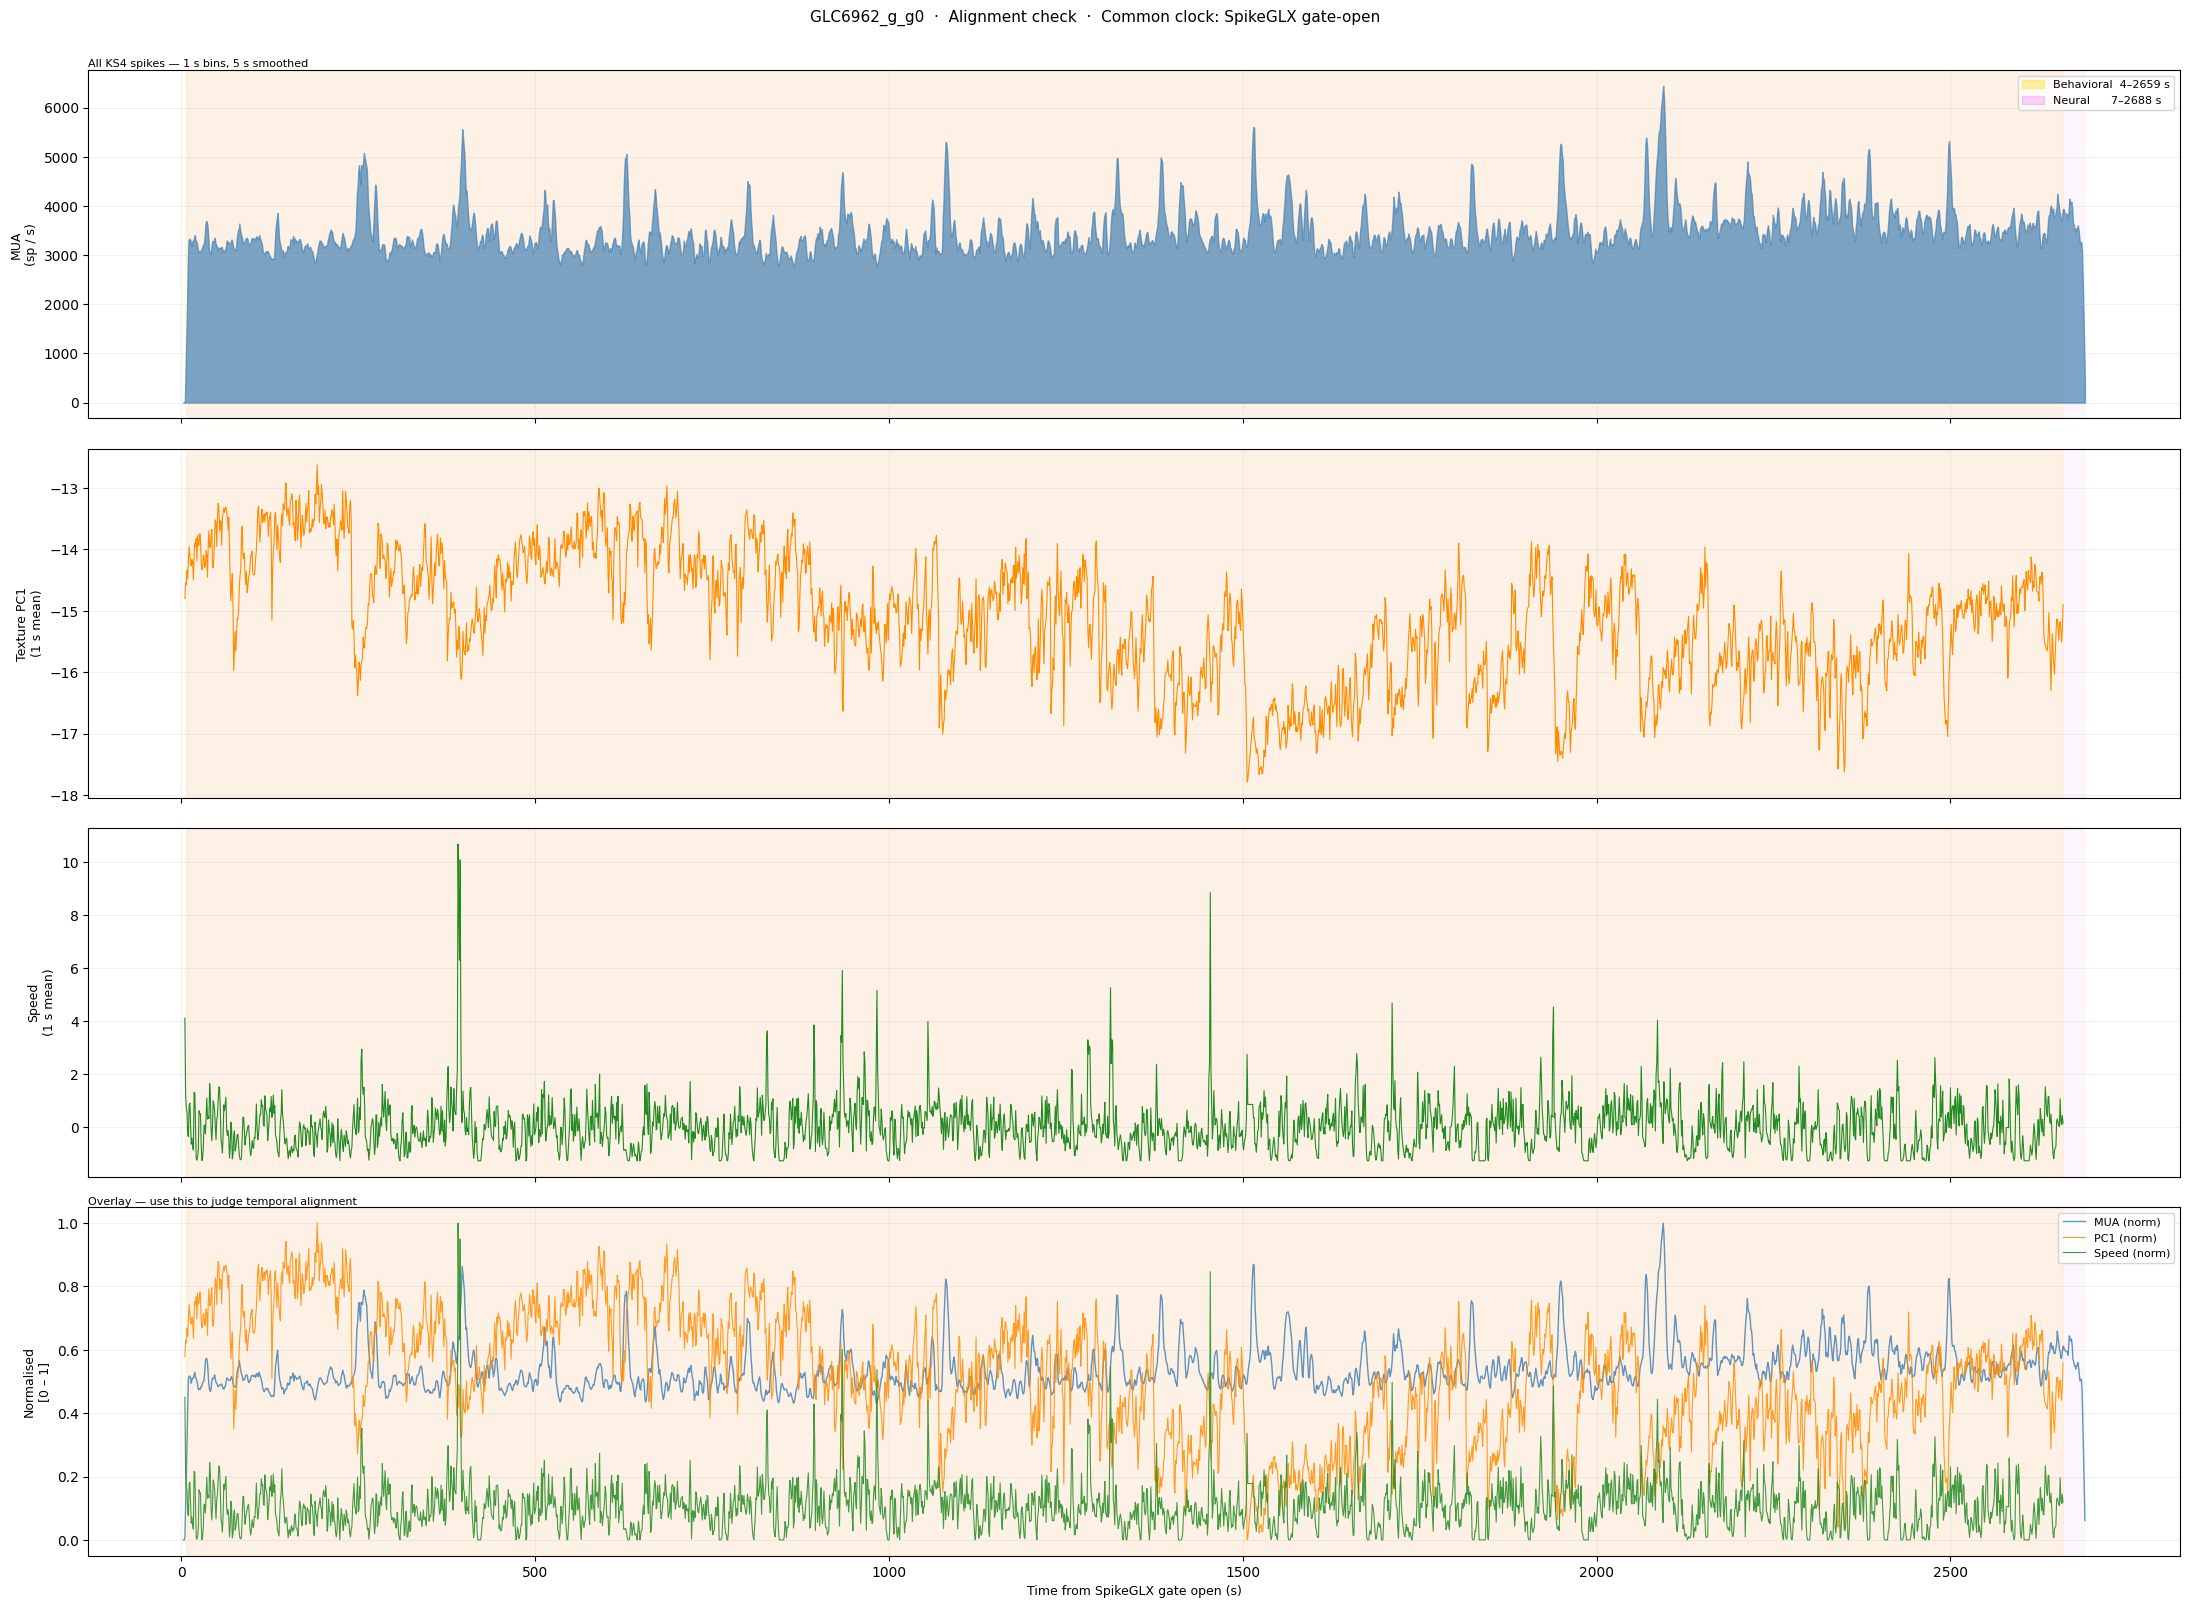

Behavioral window : 4.471 – 2658.646 s  (44.24 min)
Neural window     : 7.415 – 2687.992 s  (44.68 min)
Overlap           : 7.415 – 2658.646 s  (44.19 min)
Neural starts 2.944 s after video (gate-relative offset)


In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy.ndimage import uniform_filter1d

# ── 1. Bin MUA into 1-second windows (gate-relative time) ──────────────────
BIN_ALIGN  = 1.0   # seconds
t_lo = min(spike_t_gate.min(), beh_t.min()) - 2
t_hi = max(spike_t_gate.max(), beh_t.max()) + 2
bins_1s  = np.arange(t_lo, t_hi + BIN_ALIGN, BIN_ALIGN)
t_ctr    = (bins_1s[:-1] + bins_1s[1:]) / 2

mua_counts, _ = np.histogram(spike_t_gate, bins=bins_1s)
mua_hz = uniform_filter1d(mua_counts.astype(float) / BIN_ALIGN, size=5)  # 5 s smoothing

# ── 2. Bin behavioral signals into same windows ─────────────────────────────
def bin_signal(t_arr, sig, bins):
    out = np.full(len(bins) - 1, np.nan)
    for i in range(len(bins) - 1):
        m = (t_arr >= bins[i]) & (t_arr < bins[i + 1])
        if m.any():
            out[i] = np.nanmean(sig[m])
    return out

pc1_1s = bin_signal(beh_t, beh_pc1, bins_1s)
spd_1s = bin_signal(beh_t, beh_spd, bins_1s) if beh_spd is not None else None

# ── 3. Build normalised overlay ─────────────────────────────────────────────
def norm01(x):
    mn, mx = np.nanmin(x), np.nanmax(x)
    return (x - mn) / (mx - mn + 1e-9)

# ── 4. Plot ──────────────────────────────────────────────────────────────────
n_rows = 2 + (spd_1s is not None)
fig, axes = plt.subplots(n_rows + 1, 1, figsize=(22, 4 * (n_rows + 1)), sharex=True)
fig.suptitle(
    "GLC6962_g_g0  ·  Alignment check  ·  Common clock: SpikeGLX gate-open",
    fontsize=11, y=1.002
)

# Row 0: MUA firing rate
axes[0].fill_between(t_ctr, mua_hz, alpha=0.7, color='steelblue')
axes[0].set_ylabel("MUA\n(sp / s)", fontsize=9)
axes[0].set_title("All KS4 spikes — 1 s bins, 5 s smoothed", fontsize=8, loc='left', pad=2)

# Row 1: texture PC1
axes[1].plot(t_ctr, pc1_1s, color='darkorange', lw=0.8)
axes[1].set_ylabel("Texture PC1\n(1 s mean)", fontsize=9)

row = 2
if spd_1s is not None:
    axes[row].plot(t_ctr, spd_1s, color='forestgreen', lw=0.8)
    axes[row].set_ylabel("Speed\n(1 s mean)", fontsize=9)
    row += 1

# Last row: normalised overlay to check temporal match
ax_ov = axes[row]
ax_ov.plot(t_ctr, norm01(mua_hz),  color='steelblue',   lw=1.0, alpha=0.85, label='MUA (norm)')
ax_ov.plot(t_ctr, norm01(pc1_1s),  color='darkorange',  lw=0.8, alpha=0.85, label='PC1 (norm)')
if spd_1s is not None:
    ax_ov.plot(t_ctr, norm01(spd_1s), color='forestgreen', lw=0.8, alpha=0.85, label='Speed (norm)')
ax_ov.set_ylabel("Normalised\n[0 – 1]", fontsize=9)
ax_ov.legend(fontsize=8, loc='upper right')
ax_ov.set_title("Overlay — use this to judge temporal alignment", fontsize=8, loc='left', pad=2)

# Shade windows on every axis
beh_patch = mpatches.Patch(color='gold',   alpha=0.35, label=f"Behavioral  {beh_t.min():.0f}–{beh_t.max():.0f} s")
neu_patch = mpatches.Patch(color='violet', alpha=0.35, label=f"Neural      {ap_t_offset:.0f}–{spike_t_gate.max():.0f} s")
for ax in axes:
    ax.axvspan(beh_t.min(),   beh_t.max(),        color='gold',   alpha=0.10, zorder=0)
    ax.axvspan(ap_t_offset,   spike_t_gate.max(), color='violet', alpha=0.08, zorder=0)
    ax.grid(True, alpha=0.25, lw=0.5)

axes[0].legend(handles=[beh_patch, neu_patch], fontsize=8, loc='upper right')
axes[-1].set_xlabel("Time from SpikeGLX gate open (s)", fontsize=9)

plt.tight_layout()
plt.show()

# ── 5. Summary ───────────────────────────────────────────────────────────────
beh_dur = beh_t.max() - beh_t.min()
neu_dur = spike_t_gate.max() - ap_t_offset
ov_lo   = max(beh_t.min(), ap_t_offset)
ov_hi   = min(beh_t.max(), spike_t_gate.max())
print(f"Behavioral window : {beh_t.min():.3f} – {beh_t.max():.3f} s  ({beh_dur/60:.2f} min)")
print(f"Neural window     : {ap_t_offset:.3f} – {spike_t_gate.max():.3f} s  ({neu_dur/60:.2f} min)")
print(f"Overlap           : {ov_lo:.3f} – {ov_hi:.3f} s  ({(ov_hi-ov_lo)/60:.2f} min)")
print(f"Neural starts {ap_t_offset - beh_t.min():.3f} s after video (gate-relative offset)")


#### SPIKE POSITION VISUALISATION

Channels: 355   probe x: 0.0 – 48.0 µm   depth: 0 – 3820 µm
Spikes in 50 ms window : 263
  outside probe x range           : 200  (76%)


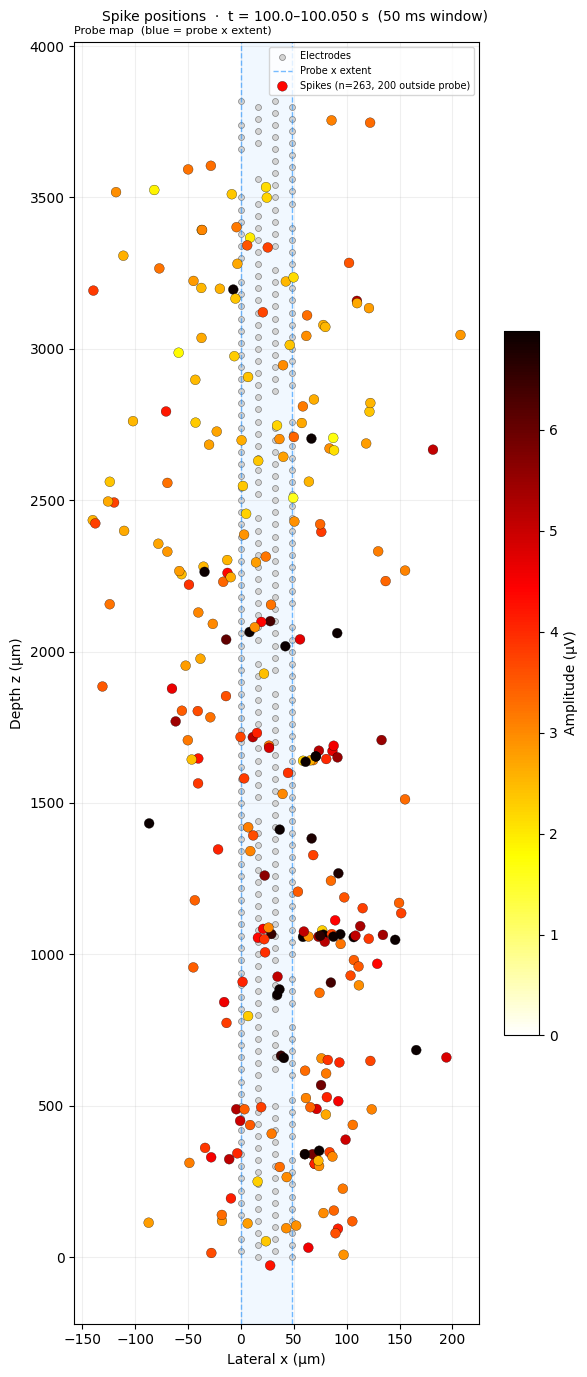

In [12]:
# ── Load channel positions from the spikeinterface saved recording ─────────────
from spikeinterface import NumpyRecording
rec_si = NumpyRecording.load(PREPROC_DIR)
ch_locs      = rec_si.get_channel_locations()   # (n_ch, 2): [x µm, depth µm]
probe_x_min  = ch_locs[:, 0].min()
probe_x_max  = ch_locs[:, 0].max()
print(f"Channels: {rec_si.get_num_channels()}   "
      f"probe x: {probe_x_min:.1f} – {probe_x_max:.1f} µm   "
      f"depth: {ch_locs[:,1].min():.0f} – {ch_locs[:,1].max():.0f} µm")

# ── Spike selection ────────────────────────────────────────────────────────────
mask    = (spike_t_gate >= T_START) & (spike_t_gate < T_START + T_WIN)
sx, sz, sa = spike_x[mask], spike_z[mask], spike_amp[mask]
outside = (sx < probe_x_min) | (sx > probe_x_max)
print(f"Spikes in {T_WIN*1e3:.0f} ms window : {mask.sum()}")
print(f"  outside probe x range           : {outside.sum()}  ({outside.mean()*100:.0f}%)")

# ── Plot — single panel ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 14))
fig.suptitle(f"Spike positions  ·  t = {T_START}–{T_START+T_WIN:.3f} s  ({T_WIN*1e3:.0f} ms window)",
             fontsize=10)

ax.scatter(ch_locs[:, 0], ch_locs[:, 1], s=18, c='lightgray',
           edgecolors='gray', linewidths=0.5, zorder=2, label='Electrodes')
ax.axvspan(probe_x_min, probe_x_max, color='dodgerblue', alpha=0.06, zorder=0)
ax.axvline(probe_x_min, color='dodgerblue', lw=1, alpha=0.6, ls='--', label='Probe x extent')
ax.axvline(probe_x_max, color='dodgerblue', lw=1, alpha=0.6, ls='--')
if mask.any():
    amp_vmax = np.percentile(spike_amp, 95)
    sc_h = ax.scatter(sx, sz, c=sa, s=50, cmap='hot_r',
                      vmin=0, vmax=amp_vmax,
                      edgecolors='k', linewidths=0.2, zorder=5,
                      label=f'Spikes (n={mask.sum()}, {outside.sum()} outside probe)')
    plt.colorbar(sc_h, ax=ax, label='Amplitude (µV)', shrink=0.55)
ax.set_xlabel('Lateral x (µm)')
ax.set_ylabel('Depth z (µm)')
ax.set_title('Probe map  (blue = probe x extent)', fontsize=8, loc='left')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


#### EXTRACT SPIKE FEATURES FOR DENSITY DECODING

In [14]:

# ── constants for spike-features pipeline ─────────────────────────────────────
# All recording metadata is taken from the already-loaded rec_si/ap_fs/ap_t_offset above.
# No re-loading is necessary.
import os
from scipy.interpolate import RegularGridInterpolator

# Paths — consistent with PREPROC_DIR defined in the NEURAL DATA cell above
BIN_FILE_SF = PREPROC_DIR + '/traces_cached_seg0.raw'
OUT_PATH    = PREPROC_DIR + '/thresholding_peaks/spike_features_GLC6962_g_g0.npz'

# All of these are derived from the recording, not hardcoded:
_n_ch    = rec_si.get_num_channels()        # 355
_fs      = rec_si.get_sampling_frequency()  # ~30000.28 Hz
_n_samp  = rec_si.get_num_samples()
_dtype   = rec_si.get_dtype()               # float16

# Waveform window (SI monopolar_triangulation convention)
SPIKE_SIZE_SF = 121    # total samples per raw waveform
TROUGH_POS_SF = 60     # trough sits at centre of window
SI_WIN_START  = TROUGH_POS_SF - 15    # 45
SI_WIN_END    = TROUGH_POS_SF + 15    # 75

print(f"Recording : {_n_ch} ch  |  {_fs:.2f} Hz  |  {_n_samp:,} samples  "
      f"({_n_samp / _fs / 60:.1f} min)  |  dtype {_dtype}")
print(f"t_start   : {ap_t_offset:.3f} s (gate-relative, from SpikeGLX firstSample)")
print(f"Binary    : {BIN_FILE_SF}")
print(f"Output    : {OUT_PATH}")
print(f"\npeaks: {len(peaks):,}   loc: {len(loc):,}   "
      f"{'aligned OK' if len(peaks)==len(loc) else 'MISMATCH!'}")
print(f"\nNote: a dredge motion-corrected binary exists for the 550–1270 s slice:")
print(f"  {PREPROC_DIR.replace('preprocessed','preprocessed_slice_550_1270s')}/rec_corrected_dredge/")
print(f"  No standalone displacement arrays were saved — correction was pre-applied to that binary.")
print(f"  For the FULL recording used here, no drift correction will be applied.")


Recording : 355 ch  |  30000.28 Hz  |  80,418,082 samples  (44.7 min)  |  dtype float16
t_start   : 7.415 s (gate-relative, from SpikeGLX firstSample)
Binary    : /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/traces_cached_seg0.raw
Output    : /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks/spike_features_GLC6962_g_g0.npz

peaks: 9,317,456   loc: 9,317,456   aligned OK

Note: a dredge motion-corrected binary exists for the 550–1270 s slice:
  /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed_slice_550_1270s/rec_corrected_dredge/
  No standalone displacement arrays were saved — correction was pre-applied to that binary.
  For the FULL recording used here, no drift correction will be applied.


SI PTP: min=0.0  median=3.7  99.9th=29.1  max=74.1  µV


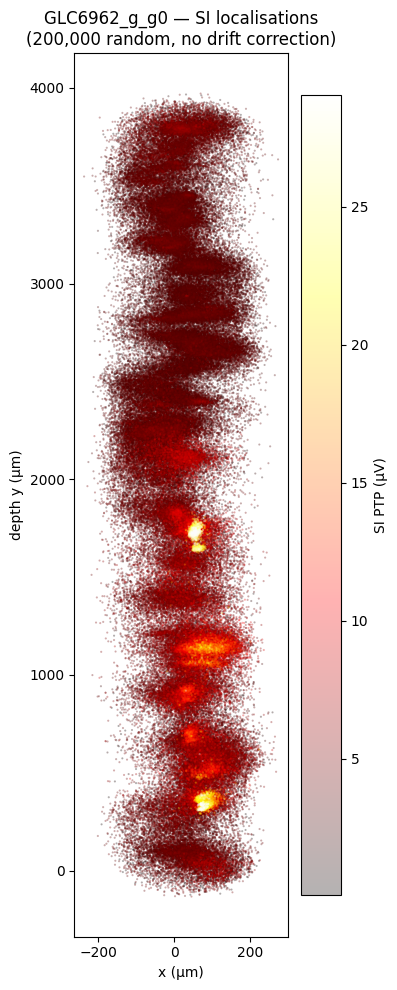

x: -288.21953559655844 – 312.30176879201053   y: -153.77567062989604 – 3991.590846564954


In [15]:

# ── SI PTP amplitude: alpha / r ───────────────────────────────────────────────
# r = distance from monopole location to the detection-channel contact
# si_ptp = alpha / r  (reconstructed PTP at the detection channel)
# ch_locs is already available from the NEURAL DATA cell above.
ch_idx_sf = peaks['channel_index']
cx_sf     = ch_locs[ch_idx_sf, 0]
cy_sf     = ch_locs[ch_idx_sf, 1]
dx_sf     = loc['x'] - cx_sf
dy_sf     = loc['y'] - cy_sf     # loc['y'] = along-probe depth of spike
dz_sf     = loc['z']              # loc['z'] = perpendicular distance from probe plane
r_sf      = np.maximum(np.sqrt(dx_sf**2 + dy_sf**2 + dz_sf**2), 1.0)
si_ptp    = (loc['alpha'] / r_sf).astype(np.float32)

p999 = float(np.percentile(si_ptp, 99.9))
print(f"SI PTP: min={si_ptp.min():.1f}  median={np.median(si_ptp):.1f}  "
      f"99.9th={p999:.1f}  max={si_ptp.max():.1f}  µV")

# ── scatter: raw localisations ─────────────────────────────────────────────────
rng_sf = np.random.default_rng(0)
n_show = min(200_000, len(loc))
isf    = rng_sf.choice(len(loc), n_show, replace=False)
isf    = isf[np.argsort(si_ptp[isf])]    # plot dim spikes first

fig, ax = plt.subplots(figsize=(4, 10))
sc = ax.scatter(loc['x'][isf], loc['y'][isf],
                c=np.clip(si_ptp[isf], 0, p999),
                s=0.3, alpha=0.3, cmap='hot', rasterized=True)
plt.colorbar(sc, ax=ax, label='SI PTP (µV)')
ax.set_xlabel('x (µm)'); ax.set_ylabel('depth y (µm)')
ax.set_title(f'GLC6962_g_g0 — SI localisations\n({n_show:,} random, no drift correction)')
plt.tight_layout(); plt.show()
print("x:", loc['x'].min(), "–", loc['x'].max(),
      "  y:", loc['y'].min(), "–", loc['y'].max())


In [16]:

# ── DREDGE DRIFT CORRECTION ────────────────────────────────────────────────────
# displacement_seg0[t, z] = probe displacement (µm) at gate-relative time t, depth z.
# Corrected depth: z_corr = z_raw − displacement(spike_t_gate, z_raw)

MOTION_DIR = PREPROC_DIR + '/thresholding_peaks/motion_estimates/motion_dredge'

displacement   = np.load(f'{MOTION_DIR}/displacement_seg0.npy')        # (n_t, n_z) float64
temporal_bins  = np.load(f'{MOTION_DIR}/temporal_bins_s_seg0.npy')     # (n_t,) gate-relative s
spatial_bins   = np.load(f'{MOTION_DIR}/spatial_bins_um.npy')          # (n_z,) depth µm

print(f"Displacement shape  : {displacement.shape}  "
      f"(t bins: {len(temporal_bins)}, z bins: {len(spatial_bins)})")
print(f"Temporal range      : {temporal_bins[0]:.2f} – {temporal_bins[-1]:.2f} s  (gate-relative)")
print(f"Spatial range       : {spatial_bins[0]:.0f} – {spatial_bins[-1]:.0f} µm")
print(f"Displacement range  : {displacement.min():.1f} – {displacement.max():.1f} µm")

z_raw = loc['y'].astype(np.float32)   # raw depth along probe (µm)

# ── METHOD A: nearest-bin lookup (same as correct_motion.py get_corrected_depths)
# For each spike, find the nearest temporal and spatial bin and read the
# displacement directly — no interpolation.
t_idx = np.clip(np.searchsorted(temporal_bins, spike_t_gate) - 1, 0, len(temporal_bins) - 1)
d_idx = np.clip(np.searchsorted(spatial_bins,  z_raw)        - 1, 0, len(spatial_bins)  - 1)
disp_at_spike = displacement[t_idx, d_idx].astype(np.float32)
z_corr = z_raw - disp_at_spike

# ── METHOD B: bilinear interpolation (commented out — swap with Method A to compare)
# from scipy.interpolate import RegularGridInterpolator
# interp_disp = RegularGridInterpolator(
#     (temporal_bins, spatial_bins), displacement,
#     method='linear', bounds_error=False, fill_value=None,
# )
# t_q = np.clip(spike_t_gate, temporal_bins[0], temporal_bins[-1])
# z_q = np.clip(z_raw,         spatial_bins[0],  spatial_bins[-1])
# disp_at_spike = interp_disp(np.column_stack([t_q, z_q])).astype(np.float32)
# z_corr = z_raw - disp_at_spike

print(f"\nz_raw   range  : {z_raw.min():.1f} – {z_raw.max():.1f} µm")
print(f"displacement   : {disp_at_spike.min():.1f} – {disp_at_spike.max():.1f} µm")
print(f"z_corr  range  : {z_corr.min():.1f} – {z_corr.max():.1f} µm")
print(f"Median abs correction : {np.median(np.abs(disp_at_spike)):.2f} µm")


Displacement shape  : (2681, 18)  (t bins: 2681, z bins: 18)
Temporal range      : 7.91 – 2687.91 s  (gate-relative)
Spatial range       : 210 – 3610 µm
Displacement range  : -93.3 – 99.0 µm



z_raw   range  : -153.8 – 3991.6 µm
displacement   : -93.3 – 99.0 µm
z_corr  range  : -173.6 – 3994.8 µm
Median abs correction : 5.99 µm


Saved → /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks/drift_scatter_before_after.png


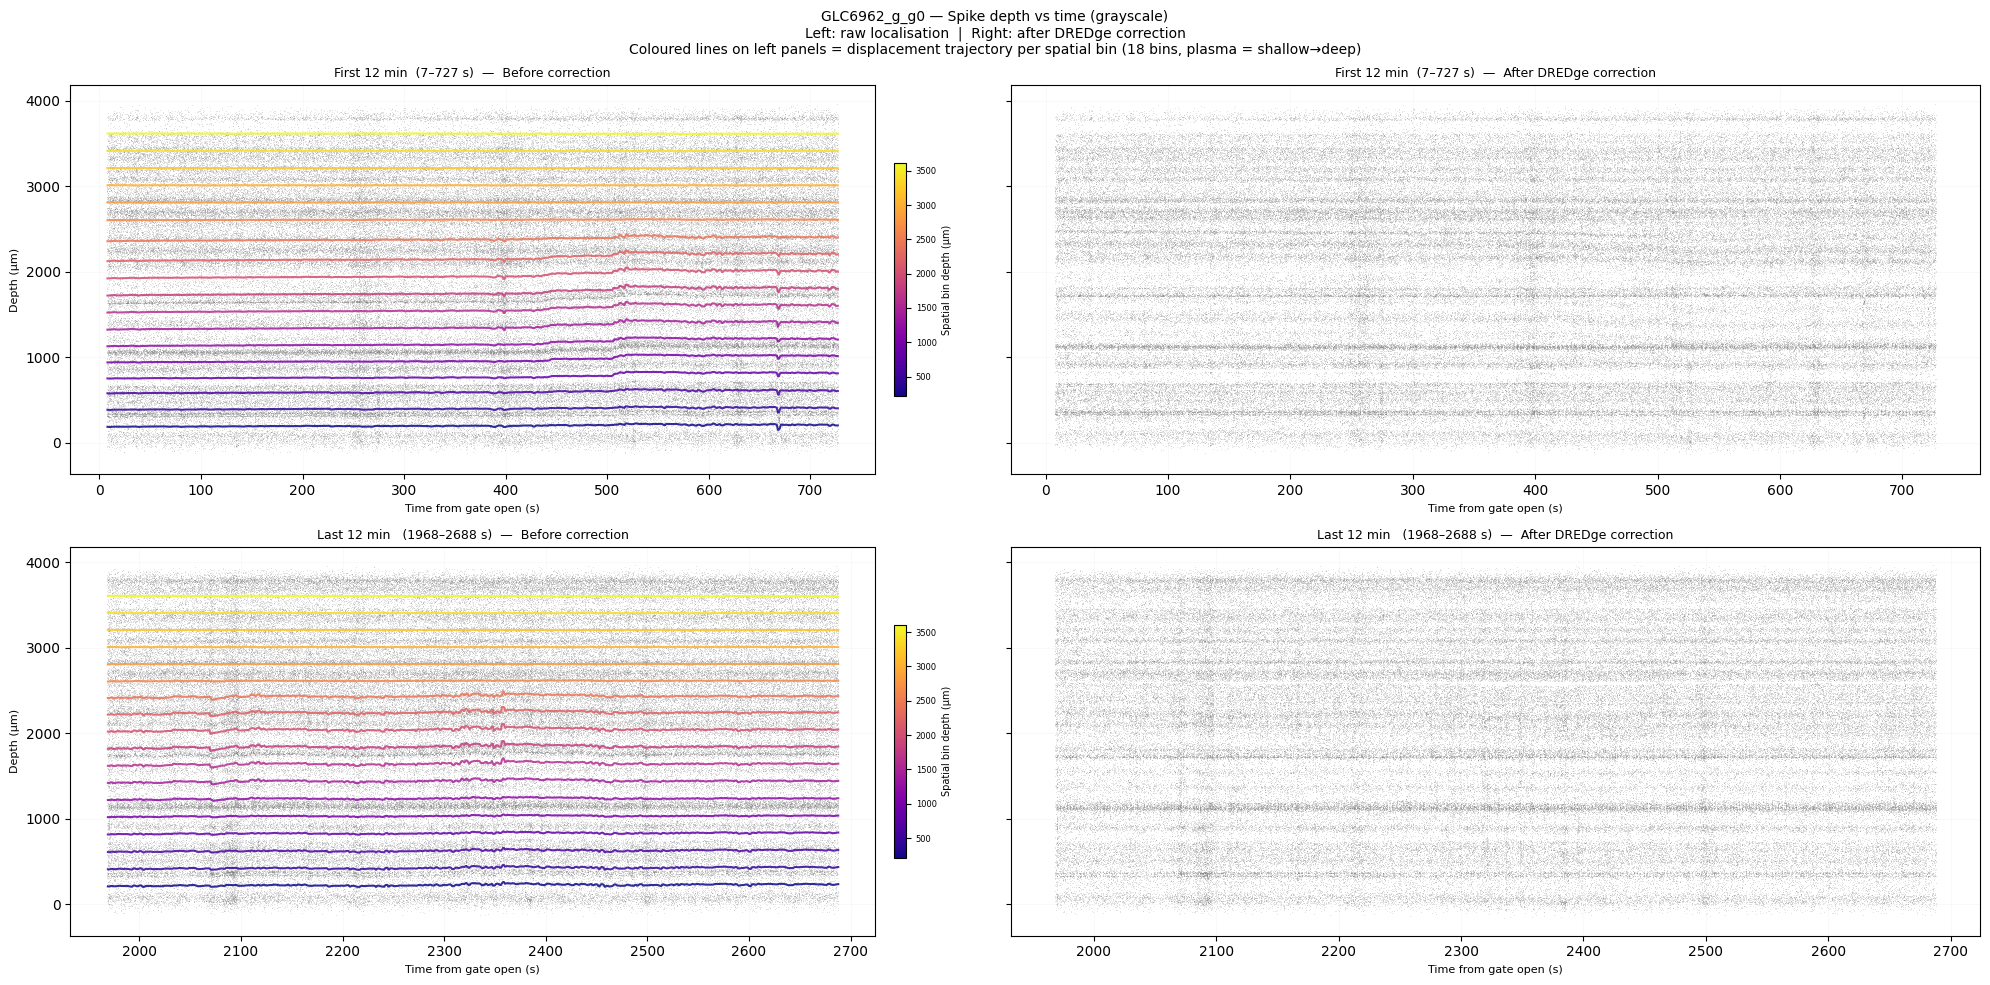

In [17]:

# ── SCATTER: SPIKE DEPTH BEFORE vs AFTER DRIFT CORRECTION ─────────────────────
# 4-panel grid: rows = first 12 min / last 12 min
#               cols = raw depth (before) / DREDge-corrected depth (after)
# Grayscale spikes; "before" panels show displacement traces for every spatial bin.
T_VIZ_S = 12 * 60    # 12 min in seconds
MAX_PTS  = 200_000   # max spikes per panel (random subsample)

t_rec_start = spike_t_gate.min()
t_rec_end   = spike_t_gate.max()
windows = [
    (f'First 12 min  ({t_rec_start:.0f}–{t_rec_start+T_VIZ_S:.0f} s)',
     t_rec_start, t_rec_start + T_VIZ_S),
    (f'Last 12 min   ({t_rec_end-T_VIZ_S:.0f}–{t_rec_end:.0f} s)',
     t_rec_end - T_VIZ_S, t_rec_end),
]

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex='row')
fig.suptitle(
    'GLC6962_g_g0 — Spike depth vs time (grayscale)\n'
    'Left: raw localisation  |  Right: after DREDge correction\n'
    'Coloured lines on left panels = displacement trajectory per spatial bin '
    f'({len(spatial_bins)} bins, plasma = shallow→deep)',
    fontsize=10,
)

rng_sc   = np.random.default_rng(7)
disp_cmap = plt.cm.plasma
disp_norm = plt.Normalize(spatial_bins[0], spatial_bins[-1])

for row_i, (win_label, t0, t1) in enumerate(windows):
    sel = np.where((spike_t_gate >= t0) & (spike_t_gate < t1))[0]
    if len(sel) > MAX_PTS:
        sel = rng_sc.choice(sel, MAX_PTS, replace=False)
        sel = sel[np.argsort(spike_t_gate[sel])]

    t_sel = spike_t_gate[sel]

    # Displacement trace mask for this time window
    t_disp = (temporal_bins >= t0) & (temporal_bins <= t1)
    t_line = temporal_bins[t_disp]

    for col_i, (z_arr, panel_title) in enumerate([
        (z_raw[sel],  'Before correction'),
        (z_corr[sel], 'After DREDge correction'),
    ]):
        ax = axes[row_i, col_i]

        # Grayscale spike scatter
        ax.scatter(t_sel, z_arr, c='gray', s=0.3, alpha=0.25,
                   rasterized=True, linewidths=0)

        # Displacement traces on "before" panels — one per spatial bin
        if col_i == 0:
            for k, z_bin in enumerate(spatial_bins):
                # Apparent position of a neuron fixed at z_bin (true depth)
                apparent = z_bin + displacement[t_disp, k]
                ax.plot(t_line, apparent,
                        color=disp_cmap(disp_norm(z_bin)),
                        lw=1.5, alpha=0.85, zorder=5)
            # Colorbar for the displacement traces
            sm = plt.cm.ScalarMappable(cmap=disp_cmap, norm=disp_norm)
            sm.set_array([])
            cb = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
            cb.set_label('Spatial bin depth (µm)', fontsize=7)
            cb.ax.tick_params(labelsize=6)

        ax.set_title(f'{win_label}  —  {panel_title}', fontsize=9)
        ax.set_xlabel('Time from gate open (s)', fontsize=8)
        if col_i == 0:
            ax.set_ylabel('Depth (µm)', fontsize=8)
        ax.grid(True, alpha=0.12, lw=0.4)

plt.tight_layout()
_scatter_save = os.path.join(os.path.dirname(OUT_PATH), 'drift_scatter_before_after.png')
plt.savefig(_scatter_save, dpi=130, bbox_inches='tight')
print(f"Saved → {_scatter_save}")
plt.show()


Random spikes: 2–5 µV
Electrode spacing 20 µm  |  column gap 16 µm  |  99th-pct PTP 8.2 µV  →  AMP_SCALE 1.7168 µm/µV


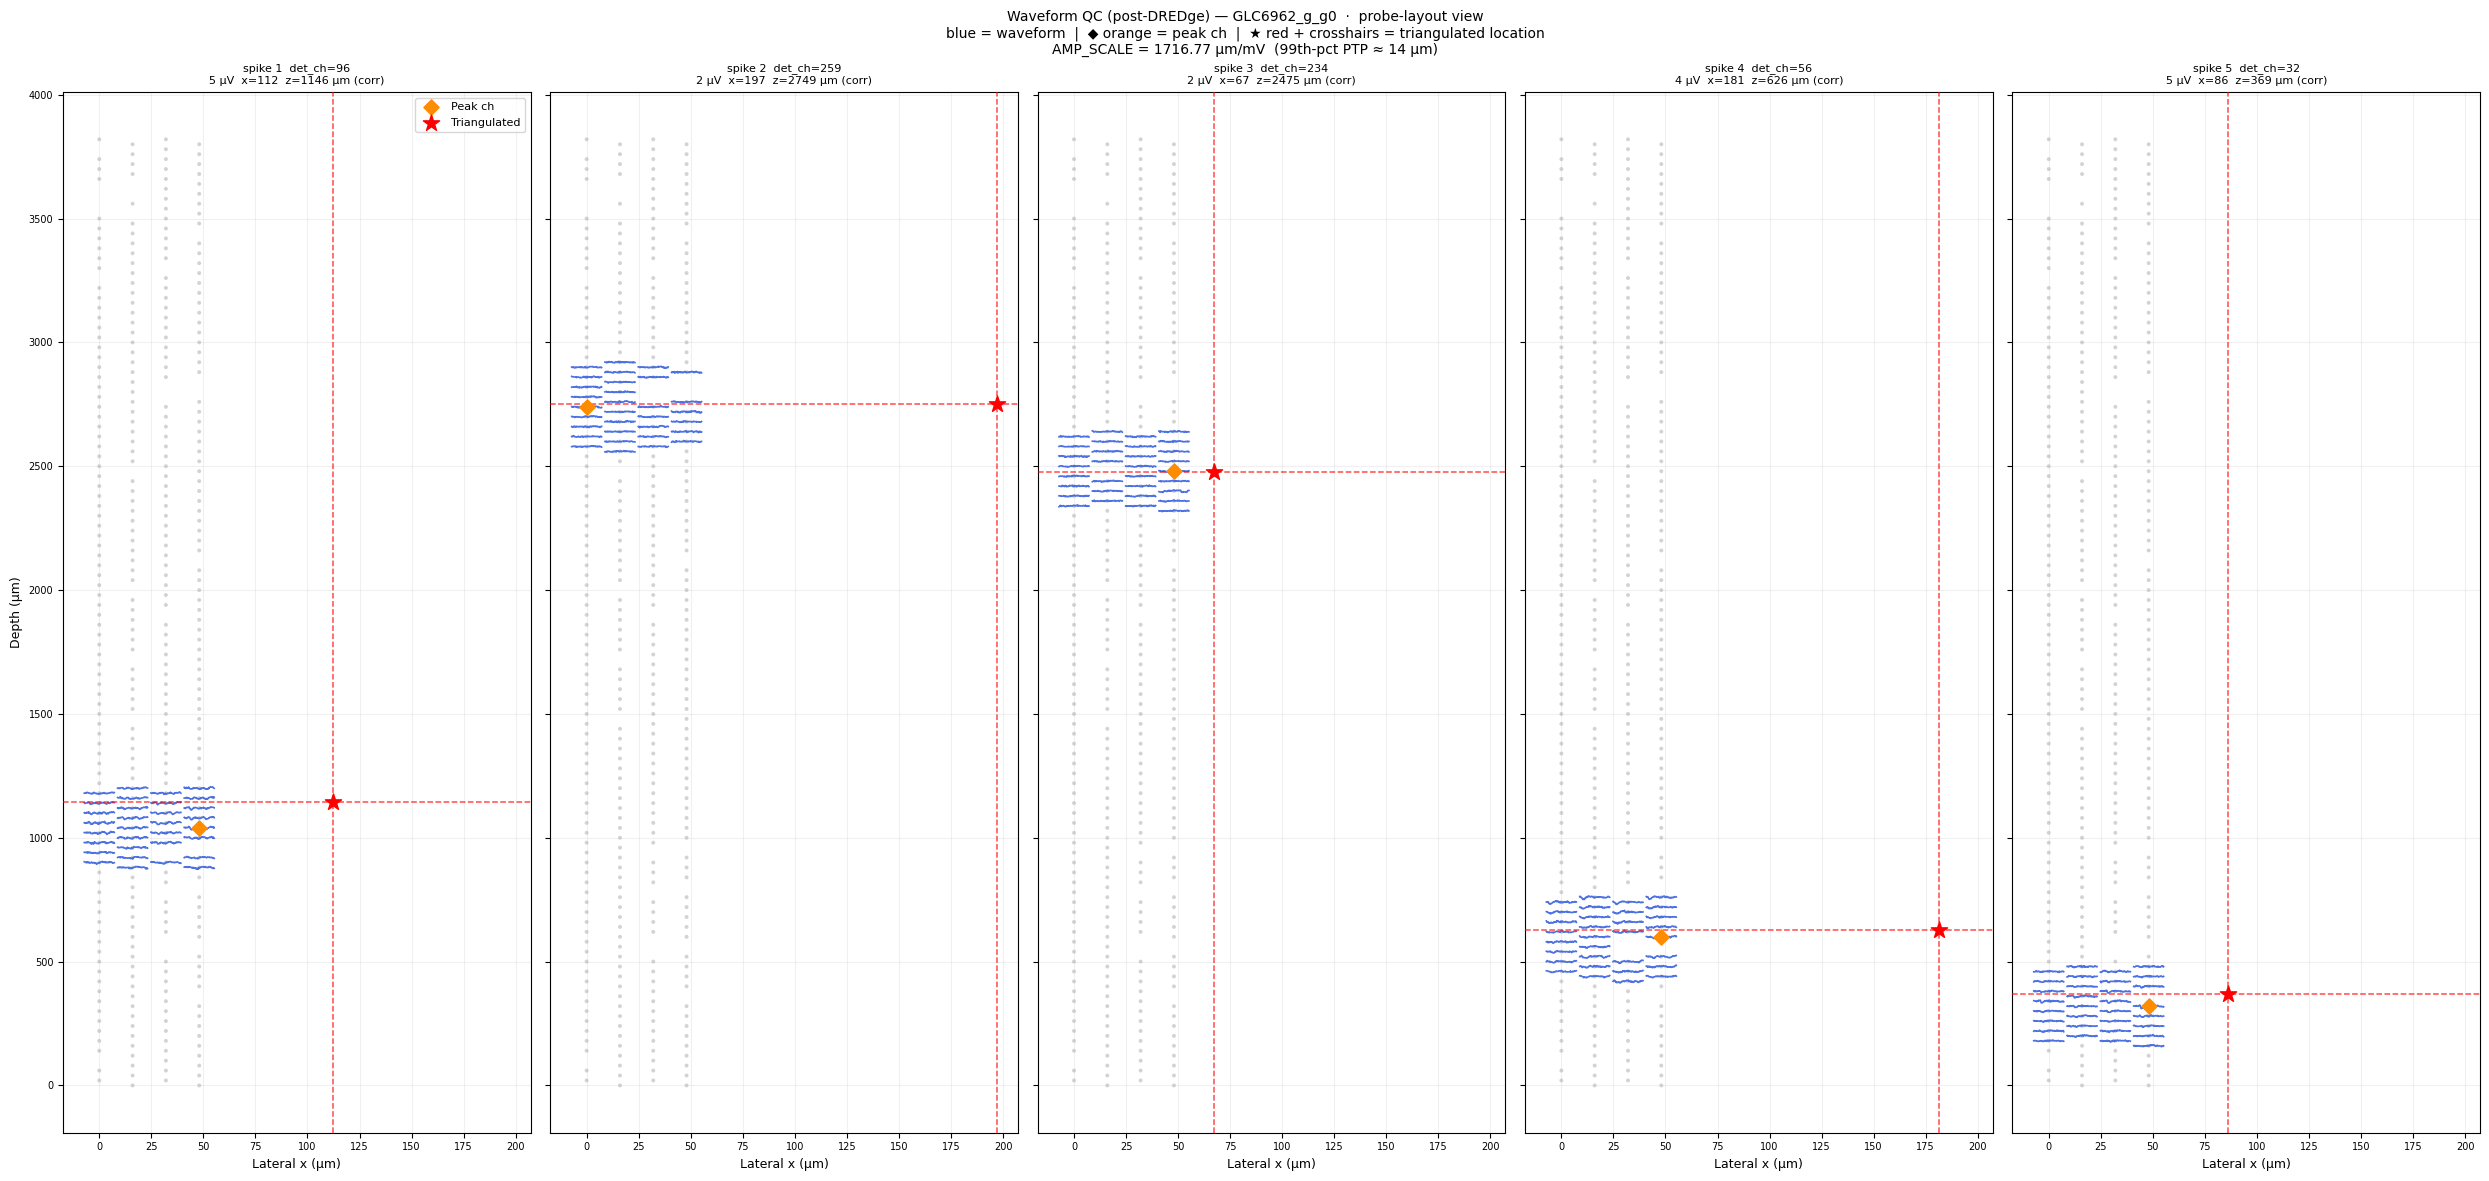

In [18]:

# ── WAVEFORM QC (post-DREDge) — probe-layout view, one panel per spike ────────
# Randomly choose 5 spikes from a short pooling window.
# Each panel = full probe layout:
#   · light-gray dots  → all electrodes at physical (x, depth) positions
#   · blue traces      → waveform on N_NBR nearest channels, drawn at their position
#   · orange ◆         → peak (detection) channel
#   · red ★ + crosshairs → monopolar-triangulated location (z_corr used for depth)
# AMP_SCALE is set so waveforms are visually clear but not overlapping excessively.
import matplotlib.pyplot as plt
import numpy as np

# ── Parameters ────────────────────────────────────────────────────────────────
T_POOL_START = 100.0    # pool spikes from this time range (s, gate-relative)
T_POOL_END   = 110.0
N_SHOW       = 5        # number of spikes to show
N_BEFORE     = 20       # samples before trough
N_AFTER      = 62       # samples after trough  (~2.7 ms @ 30 kHz)
N_NBR        = 32       # nearest channels for waveform traces

# ── Select spikes ─────────────────────────────────────────────────────────────
pool_mask = (spike_t_gate >= T_POOL_START) & (spike_t_gate < T_POOL_END)
pool_idx  = np.where(pool_mask)[0]
if len(pool_idx) < N_SHOW:
    raise ValueError(f"Not enough spikes in pooling window: found {len(pool_idx)}")
rng = np.random.default_rng(2026)
sel = rng.choice(pool_idx, N_SHOW, replace=False)
N_SPIKES = len(sel)

wf_len       = N_BEFORE + N_AFTER
n_total_samp = rec_si.get_num_samples()

# ── Electrode geometry ────────────────────────────────────────────────────────
sort_depths   = np.sort(np.unique(ch_locs[:, 1]))
elec_spacing  = float(np.median(np.diff(sort_depths)))   # µm between rows
col_xs     = np.sort(np.unique(ch_locs[:, 0]))
col_gap    = float(np.min(np.diff(col_xs))) if len(col_xs) > 1 else elec_spacing
t_um       = np.linspace(-col_gap * 0.45, col_gap * 0.45, wf_len)

# ── Read all waveforms first to compute amplitude scale ───────────────────────
all_wfs = []
all_nbr = []
for si in sel:
    pk_ch = int(peaks['channel_index'][si])
    dists = np.linalg.norm(ch_locs - ch_locs[pk_ch], axis=1)
    nbr   = np.argsort(dists)[:N_NBR]
    samp  = int(spike_times_samp[si])
    t0    = max(0, samp - N_BEFORE)
    t1    = min(n_total_samp, samp + N_AFTER)
    tr    = rec_si.get_traces(start_frame=t0, end_frame=t1)[:, nbr].astype(np.float32)
    if tr.shape[0] < wf_len:
        tr = np.pad(tr, ((0, wf_len - tr.shape[0]), (0, 0)))
    all_wfs.append(tr)
    all_nbr.append(nbr)

# Amplitude scaling: make waveforms visually clear but not overlapping
# Use 99th percentile of all channel PTPs, map to 0.7 × electrode spacing
all_ptp    = np.concatenate([np.ptp(w, axis=0) for w in all_wfs])
global_ptp = float(np.percentile(all_ptp, 99))
AMP_SCALE  = (0.7 * elec_spacing) / max(global_ptp, 1.0)   # µm / µV

print(f"Random spikes: {spike_amp[sel].min():.0f}–{spike_amp[sel].max():.0f} µV")
print(f"Electrode spacing {elec_spacing:.0f} µm  |  column gap {col_gap:.0f} µm  |  "
      f"99th-pct PTP {global_ptp:.1f} µV  →  AMP_SCALE {AMP_SCALE:.4f} µm/µV")

# ── Plot ───────────────────────────────────────────────────────────────────────
ncols = N_SHOW
nrows = 1
fig, axes = plt.subplots(nrows, ncols,
                          figsize=(ncols * 5, 12),
                          sharey=True, sharex=True)
if ncols == 1:
    axes = [axes]

fig.suptitle(
    "Waveform QC (post-DREDge) — GLC6962_g_g0  ·  probe-layout view\n"
    "blue = waveform  |  ◆ orange = peak ch  |  ★ red + crosshairs = triangulated location\n"
    f"AMP_SCALE = {AMP_SCALE*1000:.2f} µm/mV  (99th-pct PTP ≈ {0.7*elec_spacing:.0f} µm)",
    fontsize=10,
)

for pi, (si, wf, nbr) in enumerate(zip(sel, all_wfs, all_nbr)):
    ax     = axes[pi]
    pk_ch  = int(peaks['channel_index'][si])
    px     = float(spike_x[si])
    pz     = float(z_corr[si])    # DREDge-corrected depth

    # All probe electrodes — background context
    ax.scatter(ch_locs[:, 0], ch_locs[:, 1],
               s=8, c='lightgray', edgecolors='none', zorder=1, rasterized=True)

    # Waveforms at physical channel positions
    for j, ch_j in enumerate(nbr):
        xc, yc = ch_locs[ch_j, 0], ch_locs[ch_j, 1]
        ax.plot(xc + t_um, yc + wf[:, j] * AMP_SCALE,
                lw=1.2, color='royalblue', alpha=0.95, zorder=3)

    # Peak (detection) channel
    ax.scatter(ch_locs[pk_ch, 0], ch_locs[pk_ch, 1],
               s=60, c='darkorange', marker='D', zorder=5,
               label='Peak ch' if pi == 0 else None)

    # Triangulated location: dashed crosshairs + red star
    ax.axhline(pz, color='red', lw=1.1, ls='--', alpha=0.7, zorder=4)
    ax.axvline(px, color='red', lw=1.1, ls='--', alpha=0.7, zorder=4)
    ax.scatter(px, pz, s=150, c='red', marker='*', zorder=6,
               label='Triangulated' if pi == 0 else None)

    ax.set_title(
        f"spike {pi+1}  det_ch={pk_ch}\n"
        f"{spike_amp[si]:.0f} µV  x={px:.0f}  z={pz:.0f} µm (corr)",
        fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(True, alpha=0.18)
    if pi == 0:
        ax.legend(fontsize=8, loc='upper right')

# Shared axis labels
axes[0].set_ylabel('Depth (µm)', fontsize=9)
for ax in axes:
    ax.set_xlabel('Lateral x (µm)', fontsize=9)

plt.tight_layout()
plt.show()


In [19]:

# ── save spike features ───────────────────────────────────────────────────────
# Field names match the h5 fields in density_decoding/demo.ipynb:
#   times_samples, channels, denoised_ptp_amplitudes, point_source_localizations
# spike_features column order: [x, z, ptp]  = np.c_[x, z, amp]

spike_features_out = np.column_stack([
    loc['x'].astype(np.float32),    # lateral position (µm)
    z_corr,                          # depth along probe (µm, no drift correction)
    si_ptp,                          # PTP amplitude (µV)
])  # shape (N, 3)

np.savez(
    OUT_PATH,
    # ── canonical density_decoding names ────────
    times_samples              = peaks['sample_index'].astype(np.int64),
    channels                   = peaks['channel_index'].astype(np.int32),
    denoised_ptp_amplitudes    = si_ptp,
    point_source_localizations = spike_features_out,    # (N, 3): [x, z, ptp]
    # ── extras ──────────────────────────────────
    x                          = loc['x'].astype(np.float32),
    z                          = z_corr,
    t_start_gate_s             = np.float64(ap_t_offset),
    sampling_rate              = np.float64(ap_fs),
)
size_mb = os.path.getsize(OUT_PATH) / 1e6
print(f"Saved → {OUT_PATH}  ({size_mb:.0f} MB)")
print(f"  spike_features shape: {spike_features_out.shape}  dtype: {spike_features_out.dtype}")


Saved → /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks/spike_features_GLC6962_g_g0.npz  (335 MB)
  spike_features shape: (9317456, 3)  dtype: float32


In [20]:

# ── load back & prep for density decoding ─────────────────────────────────────
data = np.load(OUT_PATH, allow_pickle=False)

spike_times    = data['times_samples']              # (N,) int64 — sample indices
spike_channels = data['channels']                   # (N,) int32 — detection channel
spike_features = data['point_source_localizations'] # (N, 3) float32 — [x, z, ptp]

print("Loaded spike features:")
print(f"  spike_times    shape {spike_times.shape},    dtype {spike_times.dtype}")
print(f"  spike_channels shape {spike_channels.shape}, dtype {spike_channels.dtype}")
print(f"  spike_features shape {spike_features.shape}, dtype {spike_features.dtype}")
print(f"  columns: x (µm) | z / depth (µm) | PTP amplitude (µV)")
print()
print("Ready for density decoding pipeline:")
print("  ibl_data_loader.load_spike_features(spike_times, spike_channels, spike_features, brain_region='all')")


Loaded spike features:
  spike_times    shape (9317456,),    dtype int64
  spike_channels shape (9317456,), dtype int32
  spike_features shape (9317456, 3), dtype float32
  columns: x (µm) | z / depth (µm) | PTP amplitude (µV)

Ready for density decoding pipeline:
  ibl_data_loader.load_spike_features(spike_times, spike_channels, spike_features, brain_region='all')


#### BEHAVIOURAL DATA FOR DENSITY DECODING


PC1 raw   : min=-17.900  max=-12.503  mean=-15.126
PC2 raw   : min=-10.284  max=4.072  mean=-2.278
PC1 z     : min=-2.75  max=2.60  std=1.00
PC2 z     : min=-3.06  max=2.42  std=1.00

Overlap window: 7.41 – 2658.65 s (44.19 min)

Window length : 10.0 s  ×  30 bins = 333 ms/bin
Number of windows : 265  (~212 train, ~53 test)


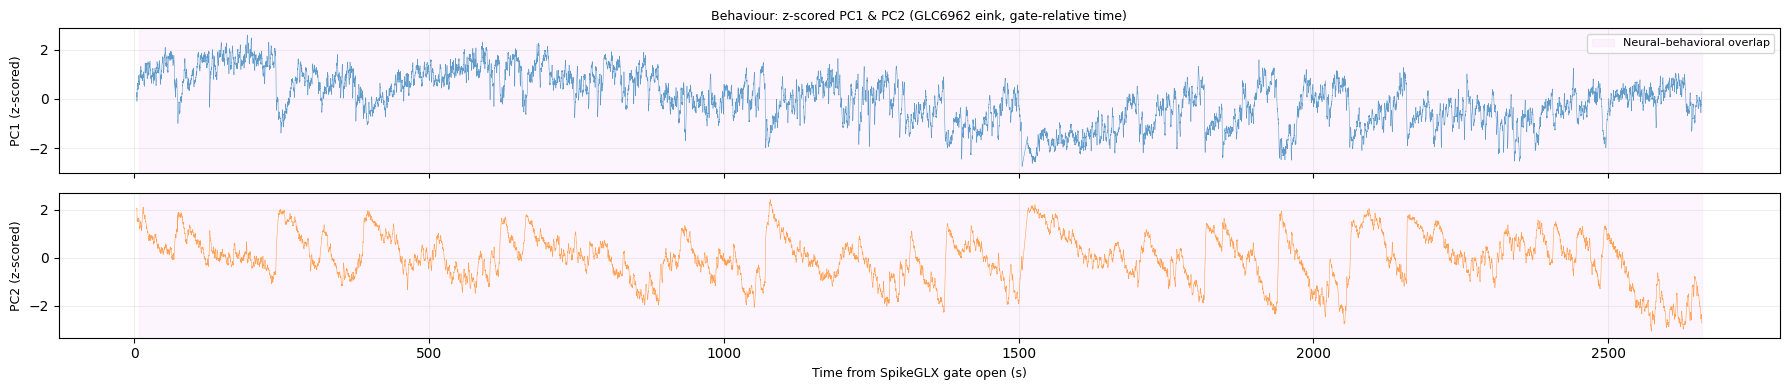

In [21]:

# ── BEHAVIOURAL DATA: PC1 & PC2 ───────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

# ── 1. Extract PCs for this session ──────────────────────────────────────────
beh_pc2 = beh['PC2'].values.astype(np.float32)   # (n_frames,)

# Z-score so both PCs are on the same scale for ADVI (behavior modulates log-λ)
beh_pc1_z = zscore(beh_pc1).astype(np.float32)
beh_pc2_z = zscore(beh_pc2).astype(np.float32)

print(f"PC1 raw   : min={beh_pc1.min():.3f}  max={beh_pc1.max():.3f}  mean={beh_pc1.mean():.3f}")
print(f"PC2 raw   : min={beh_pc2.min():.3f}  max={beh_pc2.max():.3f}  mean={beh_pc2.mean():.3f}")
print(f"PC1 z     : min={beh_pc1_z.min():.2f}  max={beh_pc1_z.max():.2f}  std={beh_pc1_z.std():.2f}")
print(f"PC2 z     : min={beh_pc2_z.min():.2f}  max={beh_pc2_z.max():.2f}  std={beh_pc2_z.std():.2f}")

# ── 2. Overlapping neural–behavioral window ───────────────────────────────────
T_OV_START = max(beh_t.min(), ap_t_offset)
T_OV_END   = min(beh_t.max(), spike_t_gate.max())
print(f"\nOverlap window: {T_OV_START:.2f} – {T_OV_END:.2f} s "
      f"({(T_OV_END - T_OV_START)/60:.2f} min)")

# ── 3. Chunk into windows (each window = one "trial" for the decoder) ─────────
# Window length chosen to be long enough that the density estimate of neural
# activity is stable (more spikes per window) and to match the timescale of
# behavioral PC dynamics (seconds, not milliseconds).
# IBL demo uses 1.5 s trials locked to stimulus; here we use 10 s free-running.
T_TRIAL    = 10.0   # seconds per window  →  ~264 windows for a 44-min overlap
N_T_BINS   = 30     # time bins per window →  10/30 ≈ 333 ms per bin

trial_starts = np.arange(T_OV_START, T_OV_END - T_TRIAL, T_TRIAL)
trial_ends   = trial_starts + T_TRIAL
n_trials_beh = len(trial_starts)
print(f"\nWindow length : {T_TRIAL} s  ×  {N_T_BINS} bins = {T_TRIAL/N_T_BINS*1000:.0f} ms/bin")
print(f"Number of windows : {n_trials_beh}  (~{n_trials_beh*0.8:.0f} train, ~{n_trials_beh*0.2:.0f} test)")

# ── 4. Quick overview plot ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(18, 4), sharex=True)
axes[0].plot(beh_t, beh_pc1_z, lw=0.4, color='tab:blue', alpha=0.7)
axes[0].set_ylabel("PC1 (z-scored)", fontsize=9)
axes[0].set_title("Behaviour: z-scored PC1 & PC2 (GLC6962 eink, gate-relative time)", fontsize=9)
axes[1].plot(beh_t, beh_pc2_z, lw=0.4, color='tab:orange', alpha=0.7)
axes[1].set_ylabel("PC2 (z-scored)", fontsize=9)
axes[1].set_xlabel("Time from SpikeGLX gate open (s)", fontsize=9)
for ax in axes:
    ax.axvspan(T_OV_START, T_OV_END, color='violet', alpha=0.08, label='Neural–behavioral overlap')
    ax.grid(True, alpha=0.2)
axes[0].legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()


In [22]:

# ── PROCESS SPIKE FEATURES & BEHAVIOURS ──────────────────────────────────────
import sys
sys.path.insert(0, '/u/gongt/density_decoding')

from density_decoding.utils.data_utils import BaseDataLoader

# Instantiate loader
data_loader = BaseDataLoader(
    t_before=0.0,
    t_after=T_TRIAL,
    n_t_bins=N_T_BINS,
)

# ── Step 1: process behaviours first (fast) to find valid windows ─────────────
print("Processing behaviour …")
_bin_beh_pc1_all = data_loader.process_behaviors(
    time_points       = beh_t,
    raw_behaviors     = beh_pc1_z,
    trial_start_times = trial_starts,
    trial_end_times   = trial_ends,
)
_bin_beh_pc2_all = data_loader.process_behaviors(
    time_points       = beh_t,
    raw_behaviors     = beh_pc2_z,
    trial_start_times = trial_starts,
    trial_end_times   = trial_ends,
)

# Windows with any NaN bin = no behavioral coverage → drop them
valid_mask   = (~np.isnan(_bin_beh_pc1_all).any(axis=1)) & \
               (~np.isnan(_bin_beh_pc2_all).any(axis=1))
valid_trials = np.where(valid_mask)[0]
n_valid      = valid_mask.sum()
print(f"Valid windows (no NaN): {n_valid} / {n_trials_beh}")

bin_beh_pc1_v = _bin_beh_pc1_all[valid_mask]   # (n_valid, N_T_BINS)
bin_beh_pc2_v = _bin_beh_pc2_all[valid_mask]

# ── Step 2: process spike features — only over valid windows ─────────────────
# Passing valid_trials= means bin_trial_idxs are 0-indexed within valid windows,
# so they align directly with train_idx / test_idx below.
print("Processing spike features (valid windows only) …")
bin_spike_features, bin_trial_idxs, bin_time_idxs = data_loader.process_spike_features(
    spike_times       = spike_t_gate,    # (N,) gate-relative seconds
    spike_channels    = spike_channels,  # (N,) int32 channel index
    spike_features    = spike_features,  # (N, 3) float32 [x µm, z µm, PTP µV]
    trial_start_times = trial_starts,
    trial_end_times   = trial_ends,
    valid_trials      = valid_trials,    # only process valid windows
)
print(f"  Done — {len(bin_spike_features)} windows binned")

# ── Temporal train / test split ───────────────────────────────────────────────
# Windows are chronologically ordered; first 80% → train, last 20% → test.
# This avoids any time-leakage and matches the continuous nature of the recording.
n_train    = int(n_valid * 0.8)
train_idx  = np.arange(n_train)            # early portion  (chronological)
test_idx   = np.arange(n_train, n_valid)   # late  portion  (chronological)

print(f"\nTemporal split  →  train: {len(train_idx)} windows  |  test: {len(test_idx)} windows")
print(f"  train covers {trial_starts[valid_trials[0]]:.1f} – "
      f"{trial_ends[valid_trials[n_train-1]]:.1f} s")
print(f"  test  covers {trial_starts[valid_trials[n_train]]:.1f} – "
      f"{trial_ends[valid_trials[-1]]:.1f} s")
print(f"\nbin_beh_pc1_v shape : {bin_beh_pc1_v.shape}")
print(f"bin_beh_pc2_v shape : {bin_beh_pc2_v.shape}")

# ── Save ──────────────────────────────────────────────────────────────────────
beh_save = os.path.join(os.path.dirname(OUT_PATH), 'beh_windows_GLC6962_g_g0.npz')
np.savez_compressed(
    beh_save,
    bin_beh_pc1    = bin_beh_pc1_v,
    bin_beh_pc2    = bin_beh_pc2_v,
    trial_starts   = trial_starts[valid_trials],
    trial_ends     = trial_ends[valid_trials],
    train_idx      = train_idx,
    test_idx       = test_idx,
    T_TRIAL        = np.float32(T_TRIAL),
    N_T_BINS       = np.int32(N_T_BINS),
)
print(f"\nSaved to: {beh_save}")


Processing behaviour …


Process behaviors: 100%|██████████| 265/265 [00:00<00:00, 1316.21it/s]


Valid windows (no NaN): 265 / 265
Processing spike features (valid windows only) …


Process spike features: 100%|██████████| 265/265 [00:11<00:00, 23.15it/s]

  Done — 265 windows binned

Temporal split  →  train: 212 windows  |  test: 53 windows
  train covers 7.4 – 2127.4 s
  test  covers 2127.4 – 2657.4 s

bin_beh_pc1_v shape : (265, 30)
bin_beh_pc2_v shape : (265, 30)

Saved to: /nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0/preprocessed/thresholding_peaks/beh_windows_GLC6962_g_g0.npz


In [23]:

# ── DENSITY DECODING — PC1 ────────────────────────────────────────────────────
import torch
from density_decoding.decode_pipeline import decode_pipeline
from density_decoding.decoders.behavior_decoder import sliding_window_decoder

device = torch.device("cpu")

print("=" * 60)
print("DECODE  PC1  (z-scored)  —  temporal train/test split")
print("=" * 60)

weight_matrix_pc1 = decode_pipeline(
    data_loader,
    bin_spike_features,   # already indexed over valid windows only
    bin_trial_idxs,
    bin_time_idxs,
    bin_behaviors  = bin_beh_pc1_v,
    behavior_type  = "continuous",
    train          = train_idx,
    test           = test_idx,
    learning_rate  = 1e-3,
    device         = device,
)

_, _, pred_pc1, metrics_pc1 = sliding_window_decoder(
    weight_matrix_pc1, bin_beh_pc1_v, train_idx, test_idx, behavior_type="continuous"
)
print(f"\nPC1 decoding  R²={metrics_pc1['r2']:.3f}  corr={metrics_pc1['corr']:.3f}")


DECODE  PC1  (z-scored)  —  temporal train/test split


Initialize GMM:  72%|███████▏  | 256/355 [46:24<17:56, 10.88s/it]


KeyboardInterrupt: 

In [ ]:

# ── DENSITY DECODING — PC2 ────────────────────────────────────────────────────
print("=" * 60)
print("DECODE  PC2  (z-scored)  —  temporal train/test split")
print("=" * 60)

weight_matrix_pc2 = decode_pipeline(
    data_loader,
    bin_spike_features,
    bin_trial_idxs,
    bin_time_idxs,
    bin_behaviors  = bin_beh_pc2_v,
    behavior_type  = "continuous",
    train          = train_idx,
    test           = test_idx,
    learning_rate  = 1e-3,
    device         = device,
)

_, _, pred_pc2, metrics_pc2 = sliding_window_decoder(
    weight_matrix_pc2, bin_beh_pc2_v, train_idx, test_idx, behavior_type="continuous"
)
print(f"\nPC2 decoding  R²={metrics_pc2['r2']:.3f}  corr={metrics_pc2['corr']:.3f}")


In [ ]:

# ── VISUALISE DECODED vs OBSERVED (test set = late portion of recording) ─────
# test_idx is already chronologically ordered (arange), so ravel() gives
# a continuous time axis matching the actual recording timeline.

t_test_start = trial_starts[valid_trials[test_idx[0]]]
t_test_end   = trial_ends[valid_trials[test_idx[-1]]]
t_ax_beh = (np.arange(len(test_idx) * N_T_BINS) * (T_TRIAL / N_T_BINS)) + t_test_start

fig, axes = plt.subplots(2, 1, figsize=(18, 5), sharex=True)
fig.suptitle(
    f"Density decoding — GLC6962_g_g0 — test set: {t_test_start:.0f}–{t_test_end:.0f} s "
    f"({(t_test_end-t_test_start)/60:.1f} min, last 20 % of recording)",
    fontsize=10
)

for ax, obs_v, pred, label, col in zip(
    axes,
    [bin_beh_pc1_v, bin_beh_pc2_v],
    [pred_pc1, pred_pc2],
    ['PC1 (z)', 'PC2 (z)'],
    ['tab:blue', 'tab:orange'],
):
    y_flat  = obs_v[test_idx].ravel()
    pr_flat = pred.ravel()
    ax.plot(t_ax_beh, y_flat,  color='darkgray', lw=0.6, label='observed')
    ax.plot(t_ax_beh, pr_flat, color=col,        lw=0.6, alpha=0.85, label='decoded')
    ax.set_ylabel(label, fontsize=9)
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel("Time from SpikeGLX gate open (s)", fontsize=9)
plt.tight_layout()
plt.show()

print(f"\nPC1: R²={metrics_pc1['r2']:.3f}   corr={metrics_pc1['corr']:.3f}   MSE={metrics_pc1['mse']:.3f}")
print(f"PC2: R²={metrics_pc2['r2']:.3f}   corr={metrics_pc2['corr']:.3f}   MSE={metrics_pc2['mse']:.3f}")


In [ ]:

# ── SAVE DECODING RESULTS ─────────────────────────────────────────────────────
import json, datetime

_out_dir   = os.path.dirname(OUT_PATH)
_decode_npz = os.path.join(_out_dir, 'decode_results_GLC6962_g_g0.npz')
_decode_txt = os.path.join(_out_dir, 'decode_results_GLC6962_g_g0.txt')
_fig_path   = os.path.join(_out_dir, 'decode_traces_GLC6962_g_g0.png')

# ── 1. Save figure ────────────────────────────────────────────────────────────
fig.savefig(_fig_path, dpi=130, bbox_inches='tight')
print(f"Figure   → {_fig_path}")

# ── 2. Save arrays needed to reproduce/evaluate decoding ─────────────────────
np.savez_compressed(
    _decode_npz,
    # Observed behaviour (all valid windows, z-scored)
    bin_beh_pc1      = bin_beh_pc1_v,           # (n_valid, N_T_BINS)
    bin_beh_pc2      = bin_beh_pc2_v,

    # Decoded predictions on the test set
    pred_pc1_test    = pred_pc1,                 # (n_test, N_T_BINS)
    pred_pc2_test    = pred_pc2,

    # Train / test split indices (into valid-window arrays above)
    train_idx        = train_idx,
    test_idx         = test_idx,

    # Learned weight matrices (one per channel per time-bin)
    weight_matrix_pc1 = weight_matrix_pc1,
    weight_matrix_pc2 = weight_matrix_pc2,

    # Window timing (gate-relative seconds)
    trial_starts_valid = trial_starts[valid_trials],
    trial_ends_valid   = trial_ends[valid_trials],

    # Parameters
    T_TRIAL  = np.float32(T_TRIAL),
    N_T_BINS = np.int32(N_T_BINS),
)
print(f"Arrays   → {_decode_npz}")

# ── 3. Save human-readable metrics summary ────────────────────────────────────
_ts = datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')
summary_lines = [
    f"Density decoding results — GLC6962_g_g0",
    f"Saved: {_ts}",
    f"",
    f"--- Design ---",
    f"  Window length : {T_TRIAL:.1f} s",
    f"  N_T_BINS      : {N_T_BINS}  ({T_TRIAL/N_T_BINS*1000:.0f} ms/bin)",
    f"  Valid windows : {n_valid}  (train={len(train_idx)}, test={len(test_idx)})",
    f"  Train period  : {trial_starts[valid_trials[train_idx[0]]]:.1f} – "
        f"{trial_ends[valid_trials[train_idx[-1]]]:.1f} s",
    f"  Test period   : {trial_starts[valid_trials[test_idx[0]]]:.1f} – "
        f"{trial_ends[valid_trials[test_idx[-1]]]:.1f} s",
    f"  Drift corr    : DREDge ({MOTION_DIR})",
    f"",
    f"--- PC1 decoding ---",
    f"  R²   : {metrics_pc1['r2']:.4f}",
    f"  corr : {metrics_pc1['corr']:.4f}",
    f"  MSE  : {metrics_pc1['mse']:.4f}",
    f"",
    f"--- PC2 decoding ---",
    f"  R²   : {metrics_pc2['r2']:.4f}",
    f"  corr : {metrics_pc2['corr']:.4f}",
    f"  MSE  : {metrics_pc2['mse']:.4f}",
]
with open(_decode_txt, 'w') as _f:
    _f.write('\n'.join(summary_lines) + '\n')
print(f"Summary  → {_decode_txt}")
print()
print('\n'.join(summary_lines))
